# Parallel & Distributed Image Processing
## Serial vs OpenMP vs MPI vs CUDA (Naive + Shared Memory)

**Course Project — Parallel & Distributed Computing**

## Objective
Implement and benchmark **five** versions of image convolution filters:
1. **Serial (CPU)** — single-threaded baseline
2. **OpenMP (CPU multi-threaded)** — shared-memory parallelism across CPU cores
3. **MPI (distributed processes)** — image split into row-blocks across processes, communicating halo rows
4. **CUDA Naive (GPU)** — one thread per pixel, global memory only
5. **CUDA Shared Memory (GPU)** — tiled implementation using shared memory

**Filters implemented**: Gaussian Blur, Sobel Edge Detection, Sharpen (all 3x3 kernels, selectable at runtime).

## Notebook structure
1. Setup & verify GPU/MPI
2. Prepare test image
3. Shared filter definitions (all 3 filters)
4. Serial implementation
5. OpenMP implementation
6. MPI implementation (distributed)
7. CUDA naive implementation
8. CUDA shared-memory implementation
9. Visual correctness check
10. Profiling with Nsight Systems / nvprof
11. Full benchmark across image sizes (all 5 methods x 3 filters)
12. Result plots and analysis
13. Report notes

## 1. Setup & Verify GPU / MPI

In [8]:
!nvidia-smi

Sat Jun 20 07:23:41 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   47C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [9]:
!pip install nvcc4jupyter -q
%load_ext nvcc4jupyter

The nvcc4jupyter extension is already loaded. To reload it, use:
  %reload_ext nvcc4jupyter


In [10]:
# Install MPI (OpenMPI) and mpi4py support, plus build tools for MPI C++
!apt-get update -q
!apt-get install -y -q openmpi-bin libopenmpi-dev
!mpic++ --version
!mpirun --version

Hit:1 https://cli.github.com/packages stable InRelease
Hit:2 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  InRelease
Hit:3 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ InRelease
Hit:4 http://security.ubuntu.com/ubuntu jammy-security InRelease
Hit:5 http://archive.ubuntu.com/ubuntu jammy InRelease
Hit:6 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu jammy InRelease
Hit:7 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu jammy InRelease
Hit:8 https://r2u.stat.illinois.edu/ubuntu jammy InRelease
Hit:9 http://archive.ubuntu.com/ubuntu jammy-updates InRelease
Hit:10 https://ppa.launchpadcontent.net/ubuntugis/ppa/ubuntu jammy InRelease
Hit:11 http://archive.ubuntu.com/ubuntu jammy-backports InRelease
Reading package lists...
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lis

## 2. Prepare Test Image

Download a sample image and convert it to grayscale (single channel, 0-255). This simplifies the convolution code — each pixel is one `unsigned char`.

Image size: (1200, 900)


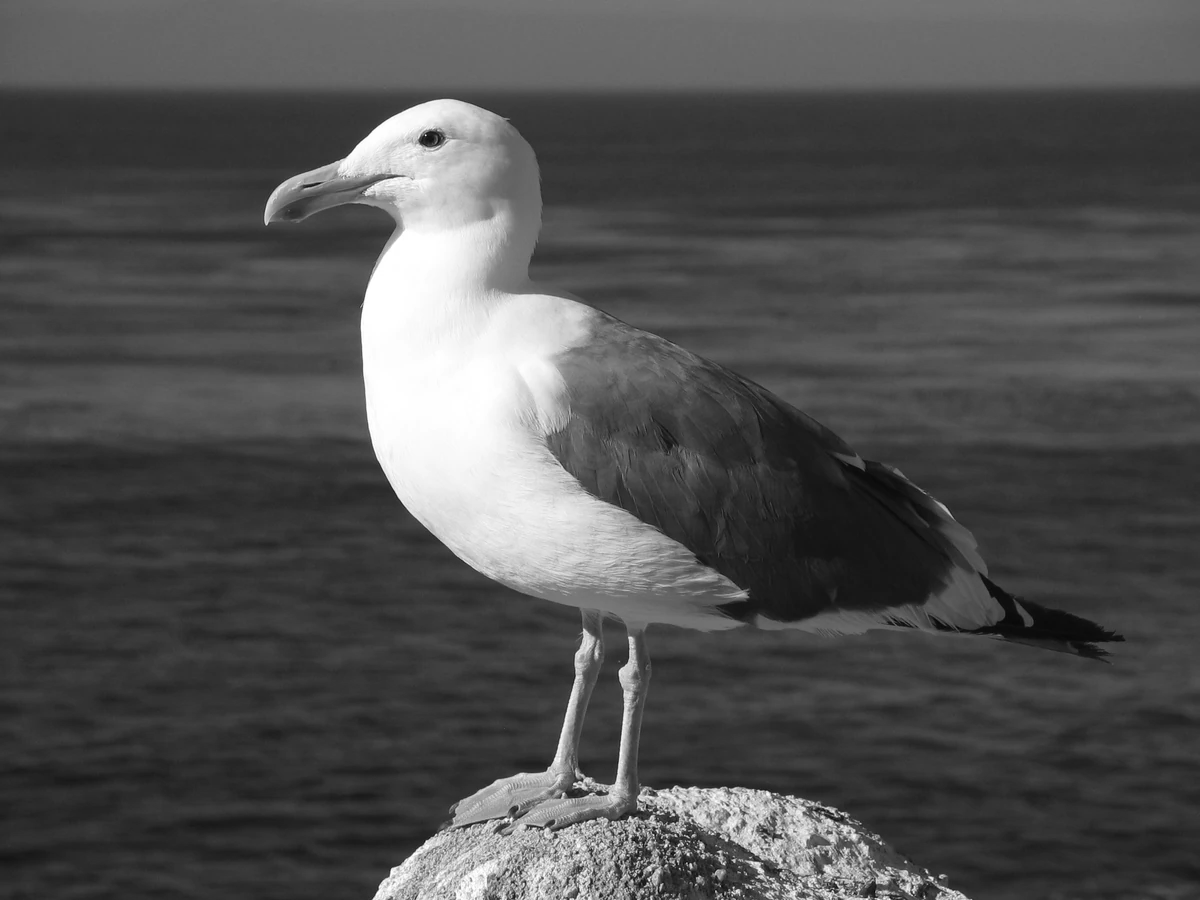

In [11]:
!wget -q -O sample.jpg https://upload.wikimedia.org/wikipedia/commons/thumb/d/dd/Gull_portrait_ca_usa.jpg/640px-Gull_portrait_ca_usa.jpg

from PIL import Image
import numpy as np

img = Image.open('/content/seagull.jpg').convert('L')
print('Image size:', img.size)
img

In [12]:
arr = np.array(img, dtype=np.uint8)
height, width = arr.shape
print(f'Width: {width}, Height: {height}')

arr.tofile('image.bin')
with open('image_dims.txt', 'w') as f:
    f.write(f'{width} {height}')

Width: 1200, Height: 900


## 3. Filter Definitions

All implementations support **3 filters**, selected via a command-line argument: `0` = Gaussian Blur, `1` = Sobel Edge Detection, `2` = Sharpen.

| ID | Filter | Kernel | Notes |
|----|--------|--------|-------|
| 0 | Gaussian Blur | smoothing kernel, sum=16 | softens image, removes noise |
| 1 | Sobel | gradient magnitude from Gx+Gy | highlights edges |
| 2 | Sharpen | high-pass kernel, sum=1 | enhances detail/contrast |

These kernel definitions are duplicated (as plain arrays) inside each source file below so every implementation is self-contained and independently compilable/runnable — this matches how most parallel-computing course submissions are structured (one file per technique).

## 4. Serial (CPU, single-threaded) Implementation

Baseline. Usage: `./serial <filter_id>` where filter_id is 0 (Gaussian), 1 (Sobel), or 2 (Sharpen).

In [13]:
%%writefile serial.cpp
#include <iostream>
#include <fstream>
#include <vector>
#include <chrono>
#include <cmath>
#include <cstdint>
#include <cstdlib>

using namespace std;
using namespace std::chrono;

float GAUSSIAN[3][3] = {
    {1.0f/16, 2.0f/16, 1.0f/16},
    {2.0f/16, 4.0f/16, 2.0f/16},
    {1.0f/16, 2.0f/16, 1.0f/16}
};
float SOBEL_X[3][3] = {{-1,0,1},{-2,0,2},{-1,0,1}};
float SOBEL_Y[3][3] = {{-1,-2,-1},{0,0,0},{1,2,1}};
float SHARPEN[3][3] = {{0,-1,0},{-1,5,-1},{0,-1,0}};

const char* FILTER_NAMES[3] = {"Gaussian", "Sobel", "Sharpen"};

// Standard single-kernel convolution (Gaussian, Sharpen)
void applyFilter(const vector<unsigned char>& input, vector<unsigned char>& output,
                  int width, int height, float kernel[3][3]) {
    for (int y = 0; y < height; y++) {
        for (int x = 0; x < width; x++) {
            float sum = 0.0f;
            for (int ky = -1; ky <= 1; ky++) {
                for (int kx = -1; kx <= 1; kx++) {
                    int yy = min(max(y + ky, 0), height - 1);
                    int xx = min(max(x + kx, 0), width - 1);
                    sum += input[yy * width + xx] * kernel[ky + 1][kx + 1];
                }
            }
            sum = max(0.0f, min(255.0f, sum));
            output[y * width + x] = (unsigned char)sum;
        }
    }
}

// Sobel: combine Gx and Gy into gradient magnitude
void applySobel(const vector<unsigned char>& input, vector<unsigned char>& output,
                int width, int height) {
    for (int y = 0; y < height; y++) {
        for (int x = 0; x < width; x++) {
            float gx = 0.0f, gy = 0.0f;
            for (int ky = -1; ky <= 1; ky++) {
                for (int kx = -1; kx <= 1; kx++) {
                    int yy = min(max(y + ky, 0), height - 1);
                    int xx = min(max(x + kx, 0), width - 1);
                    unsigned char p = input[yy * width + xx];
                    gx += p * SOBEL_X[ky + 1][kx + 1];
                    gy += p * SOBEL_Y[ky + 1][kx + 1];
                }
            }
            float mag = sqrtf(gx * gx + gy * gy);
            mag = max(0.0f, min(255.0f, mag));
            output[y * width + x] = (unsigned char)mag;
        }
    }
}

int main(int argc, char** argv) {
    int filterId = (argc > 1) ? atoi(argv[1]) : 0; // default Gaussian

    int width, height;
    ifstream dimFile("image_dims.txt");
    dimFile >> width >> height;
    dimFile.close();

    vector<unsigned char> input(width * height);
    ifstream imgFile("image.bin", ios::binary);
    imgFile.read((char*)input.data(), width * height);
    imgFile.close();

    vector<unsigned char> output(width * height);

    auto start = high_resolution_clock::now();
    if (filterId == 0) applyFilter(input, output, width, height, GAUSSIAN);
    else if (filterId == 1) applySobel(input, output, width, height);
    else applyFilter(input, output, width, height, SHARPEN);
    auto end = high_resolution_clock::now();

    double ms = duration_cast<duration<double, milli>>(end - start).count();
    cout << "Serial " << FILTER_NAMES[filterId] << ": " << ms << " ms (" << width << "x" << height << ")" << endl;

    ofstream outFile("output_serial_" + to_string(filterId) + ".bin", ios::binary);
    outFile.write((char*)output.data(), width * height);
    outFile.close();

    return 0;
}

Writing serial.cpp


In [14]:
!g++ -O2 serial.cpp -o serial
!./serial 0   # Gaussian
!./serial 1   # Sobel
!./serial 2   # Sharpen

Serial Gaussian: 17.737 ms (1200x900)
Serial Sobel: 24.3273 ms (1200x900)
Serial Sharpen: 23.9995 ms (1200x900)


## 5. OpenMP (Multi-core CPU) Implementation

Same algorithms, with the pixel loop parallelized via `#pragma omp parallel for collapse(2)`.

In [15]:
%%writefile openmp_filter.cpp
#include <iostream>
#include <fstream>
#include <vector>
#include <chrono>
#include <cmath>
#include <cstdlib>
#include <omp.h>

using namespace std;
using namespace std::chrono;

float GAUSSIAN[3][3] = {
    {1.0f/16, 2.0f/16, 1.0f/16},
    {2.0f/16, 4.0f/16, 2.0f/16},
    {1.0f/16, 2.0f/16, 1.0f/16}
};
float SOBEL_X[3][3] = {{-1,0,1},{-2,0,2},{-1,0,1}};
float SOBEL_Y[3][3] = {{-1,-2,-1},{0,0,0},{1,2,1}};
float SHARPEN[3][3] = {{0,-1,0},{-1,5,-1},{0,-1,0}};

const char* FILTER_NAMES[3] = {"Gaussian", "Sobel", "Sharpen"};

void applyFilterOMP(const vector<unsigned char>& input, vector<unsigned char>& output,
                     int width, int height, float kernel[3][3]) {
    #pragma omp parallel for collapse(2) schedule(static)
    for (int y = 0; y < height; y++) {
        for (int x = 0; x < width; x++) {
            float sum = 0.0f;
            for (int ky = -1; ky <= 1; ky++) {
                for (int kx = -1; kx <= 1; kx++) {
                    int yy = min(max(y + ky, 0), height - 1);
                    int xx = min(max(x + kx, 0), width - 1);
                    sum += input[yy * width + xx] * kernel[ky + 1][kx + 1];
                }
            }
            sum = max(0.0f, min(255.0f, sum));
            output[y * width + x] = (unsigned char)sum;
        }
    }
}

void applySobelOMP(const vector<unsigned char>& input, vector<unsigned char>& output,
                   int width, int height) {
    #pragma omp parallel for collapse(2) schedule(static)
    for (int y = 0; y < height; y++) {
        for (int x = 0; x < width; x++) {
            float gx = 0.0f, gy = 0.0f;
            for (int ky = -1; ky <= 1; ky++) {
                for (int kx = -1; kx <= 1; kx++) {
                    int yy = min(max(y + ky, 0), height - 1);
                    int xx = min(max(x + kx, 0), width - 1);
                    unsigned char p = input[yy * width + xx];
                    gx += p * SOBEL_X[ky + 1][kx + 1];
                    gy += p * SOBEL_Y[ky + 1][kx + 1];
                }
            }
            float mag = sqrtf(gx * gx + gy * gy);
            mag = max(0.0f, min(255.0f, mag));
            output[y * width + x] = (unsigned char)mag;
        }
    }
}

int main(int argc, char** argv) {
    int filterId = (argc > 1) ? atoi(argv[1]) : 0;

    int width, height;
    ifstream dimFile("image_dims.txt");
    dimFile >> width >> height;
    dimFile.close();

    vector<unsigned char> input(width * height);
    ifstream imgFile("image.bin", ios::binary);
    imgFile.read((char*)input.data(), width * height);
    imgFile.close();

    vector<unsigned char> output(width * height);

    cout << "Using " << omp_get_max_threads() << " threads" << endl;

    auto start = high_resolution_clock::now();
    if (filterId == 0) applyFilterOMP(input, output, width, height, GAUSSIAN);
    else if (filterId == 1) applySobelOMP(input, output, width, height);
    else applyFilterOMP(input, output, width, height, SHARPEN);
    auto end = high_resolution_clock::now();

    double ms = duration_cast<duration<double, milli>>(end - start).count();
    cout << "OpenMP " << FILTER_NAMES[filterId] << ": " << ms << " ms (" << width << "x" << height << ")" << endl;

    ofstream outFile("output_openmp_" + to_string(filterId) + ".bin", ios::binary);
    outFile.write((char*)output.data(), width * height);
    outFile.close();

    return 0;
}

Writing openmp_filter.cpp


In [16]:
!g++ -O2 -fopenmp openmp_filter.cpp -o openmp_filter
!OMP_NUM_THREADS=4 ./openmp_filter 0
!OMP_NUM_THREADS=4 ./openmp_filter 1
!OMP_NUM_THREADS=4 ./openmp_filter 2

Using 4 threads
OpenMP Gaussian: 17.9187 ms (1200x900)
Using 4 threads
OpenMP Sobel: 35.9629 ms (1200x900)
Using 4 threads
OpenMP Sharpen: 24.6727 ms (1200x900)


## 6. MPI (Distributed) Implementation

This is the **distributed-computing** component. The image is split into horizontal row-blocks, one per MPI process. Because a 3x3 convolution needs neighboring rows, each process exchanges **halo rows** (one row above, one below) with its neighbors using `MPI_Sendrecv` before computing its block. Process 0 then gathers all blocks back into the final image with `MPI_Gather`.

**Key distributed-systems concepts demonstrated**: domain decomposition, halo/ghost-cell exchange, point-to-point communication, and collective communication (gather).

In [17]:
%%writefile mpi_filter.cpp
#include <mpi.h>
#include <iostream>
#include <fstream>
#include <vector>
#include <cmath>
#include <cstdlib>

using namespace std;

float GAUSSIAN[3][3] = {
    {1.0f/16, 2.0f/16, 1.0f/16},
    {2.0f/16, 4.0f/16, 2.0f/16},
    {1.0f/16, 2.0f/16, 1.0f/16}
};
float SOBEL_X[3][3] = {{-1,0,1},{-2,0,2},{-1,0,1}};
float SOBEL_Y[3][3] = {{-1,-2,-1},{0,0,0},{1,2,1}};
float SHARPEN[3][3] = {{0,-1,0},{-1,5,-1},{0,-1,0}};

const char* FILTER_NAMES[3] = {"Gaussian", "Sobel", "Sharpen"};

// Apply filter to local block; localRows includes halo rows at top/bottom
// (except for rank 0 / last rank at image boundary, where edge clamping is used)
void applyToBlock(const vector<unsigned char>& localIn, vector<unsigned char>& localOut,
                   int width, int localRows, int filterId, bool hasTopHalo, bool hasBottomHalo) {
    // localIn has (localRows + topHalo + bottomHalo) rows; row 0 of output
    // corresponds to row (hasTopHalo?1:0) of localIn
    int topOffset = hasTopHalo ? 1 : 0;

    for (int y = 0; y < localRows; y++) {
        for (int x = 0; x < width; x++) {
            int srcY = y + topOffset;
            if (filterId == 1) {
                float gx = 0.0f, gy = 0.0f;
                for (int ky = -1; ky <= 1; ky++) {
                    for (int kx = -1; kx <= 1; kx++) {
                        int yy = srcY + ky;
                        int xx = min(max(x + kx, 0), width - 1);
                        // clamp yy within available local rows (handles image top/bottom edges)
                        yy = min(max(yy, 0), (int)(localIn.size() / width) - 1);
                        unsigned char p = localIn[yy * width + xx];
                        gx += p * SOBEL_X[ky + 1][kx + 1];
                        gy += p * SOBEL_Y[ky + 1][kx + 1];
                    }
                }
                float mag = sqrtf(gx * gx + gy * gy);
                mag = max(0.0f, min(255.0f, mag));
                localOut[y * width + x] = (unsigned char)mag;
            } else {
                float (*kernel)[3] = (filterId == 0) ? GAUSSIAN : SHARPEN;
                float sum = 0.0f;
                for (int ky = -1; ky <= 1; ky++) {
                    for (int kx = -1; kx <= 1; kx++) {
                        int yy = srcY + ky;
                        int xx = min(max(x + kx, 0), width - 1);
                        yy = min(max(yy, 0), (int)(localIn.size() / width) - 1);
                        sum += localIn[yy * width + xx] * kernel[ky + 1][kx + 1];
                    }
                }
                sum = max(0.0f, min(255.0f, sum));
                localOut[y * width + x] = (unsigned char)sum;
            }
        }
    }
}

int main(int argc, char** argv) {
    MPI_Init(&argc, &argv);
    int rank, numProcs;
    MPI_Comm_rank(MPI_COMM_WORLD, &rank);
    MPI_Comm_size(MPI_COMM_WORLD, &numProcs);

    int filterId = (argc > 1) ? atoi(argv[1]) : 0;

    int width, height;
    if (rank == 0) {
        ifstream dimFile("image_dims.txt");
        dimFile >> width >> height;
        dimFile.close();
    }
    MPI_Bcast(&width, 1, MPI_INT, 0, MPI_COMM_WORLD);
    MPI_Bcast(&height, 1, MPI_INT, 0, MPI_COMM_WORLD);

    // Row-decomposition: each rank gets ~height/numProcs rows
    int baseRows = height / numProcs;
    int remainder = height % numProcs;
    int localRows = baseRows + (rank < remainder ? 1 : 0);

    // Compute starting row offset for this rank
    int startRow = rank * baseRows + min(rank, remainder);

    // Load full image on rank 0, scatter row-blocks
    vector<unsigned char> fullImage;
    if (rank == 0) {
        fullImage.resize(width * height);
        ifstream imgFile("image.bin", ios::binary);
        imgFile.read((char*)fullImage.data(), width * height);
        imgFile.close();
    }

    // Scatter using Scatterv (variable counts since rows may differ by 1)
    vector<int> sendCounts(numProcs), displs(numProcs);
    if (rank == 0) {
        for (int r = 0; r < numProcs; r++) {
            int rRows = baseRows + (r < remainder ? 1 : 0);
            int rStart = r * baseRows + min(r, remainder);
            sendCounts[r] = rRows * width;
            displs[r] = rStart * width;
        }
    }

    vector<unsigned char> localData(localRows * width);
    MPI_Scatterv(rank == 0 ? fullImage.data() : nullptr, sendCounts.data(), displs.data(),
                  MPI_UNSIGNED_CHAR, localData.data(), localRows * width, MPI_UNSIGNED_CHAR,
                  0, MPI_COMM_WORLD);

    // Halo exchange: send/receive boundary rows with neighbors
    bool hasTop = (rank > 0);
    bool hasBottom = (rank < numProcs - 1);

    int extendedRows = localRows + (hasTop ? 1 : 0) + (hasBottom ? 1 : 0);
    vector<unsigned char> extendedData(extendedRows * width);

    int copyOffset = hasTop ? width : 0;
    copy(localData.begin(), localData.end(), extendedData.begin() + copyOffset);

    MPI_Request reqs[4];
    int reqCount = 0;

    // exchange last row with rank+1, first row with rank-1
    if (hasBottom) {
        MPI_Isend(localData.data() + (localRows - 1) * width, width, MPI_UNSIGNED_CHAR, rank + 1, 0, MPI_COMM_WORLD, &reqs[reqCount++]);
        MPI_Irecv(extendedData.data() + (extendedRows - 1) * width, width, MPI_UNSIGNED_CHAR, rank + 1, 1, MPI_COMM_WORLD, &reqs[reqCount++]);
    }
    if (hasTop) {
        MPI_Isend(localData.data(), width, MPI_UNSIGNED_CHAR, rank - 1, 1, MPI_COMM_WORLD, &reqs[reqCount++]);
        MPI_Irecv(extendedData.data(), width, MPI_UNSIGNED_CHAR, rank - 1, 0, MPI_COMM_WORLD, &reqs[reqCount++]);
    }
    MPI_Waitall(reqCount, reqs, MPI_STATUSES_IGNORE);

    vector<unsigned char> localOut(localRows * width);

    double startTime = MPI_Wtime();
    applyToBlock(extendedData, localOut, width, localRows, filterId, hasTop, hasBottom);
    double endTime = MPI_Wtime();

    double localMs = (endTime - startTime) * 1000.0;
    double maxMs;
    MPI_Reduce(&localMs, &maxMs, 1, MPI_DOUBLE, MPI_MAX, 0, MPI_COMM_WORLD);

    // Gather results back to rank 0
    vector<unsigned char> result;
    if (rank == 0) result.resize(width * height);
    MPI_Gatherv(localOut.data(), localRows * width, MPI_UNSIGNED_CHAR,
                rank == 0 ? result.data() : nullptr, sendCounts.data(), displs.data(),
                MPI_UNSIGNED_CHAR, 0, MPI_COMM_WORLD);

    if (rank == 0) {
        cout << "MPI (" << numProcs << " procs) " << FILTER_NAMES[filterId] << ": "
             << maxMs << " ms (" << width << "x" << height << ")" << endl;
        ofstream outFile("output_mpi_" + to_string(filterId) + ".bin", ios::binary);
        outFile.write((char*)result.data(), width * height);
        outFile.close();
    }

    MPI_Finalize();
    return 0;
}

Writing mpi_filter.cpp


In [18]:
!mpic++ -O2 mpi_filter.cpp -o mpi_filter
# Run with 4 processes. --allow-run-as-root needed in Colab.
!mpirun --allow-run-as-root --oversubscribe -np 4 ./mpi_filter 0
!mpirun --allow-run-as-root --oversubscribe -np 4 ./mpi_filter 1
!mpirun --allow-run-as-root --oversubscribe -np 4 ./mpi_filter 2

MPI (4 procs) Gaussian: 46.5327 ms (1200x900)
MPI (4 procs) Sobel: 53.4553 ms (1200x900)
MPI (4 procs) Sharpen: 46.9431 ms (1200x900)


## 7. CUDA Naive Implementation (one thread per pixel)

Each GPU thread computes one output pixel, reading its 3x3 neighborhood directly from global memory. Filter selectable via command-line argument.

In [19]:
%%writefile cuda_naive.cu
#include <iostream>
#include <fstream>
#include <vector>
#include <cstdio>
#include <cstdlib>

using namespace std;

__constant__ float d_gaussian[3][3] = {
    {1.0f/16, 2.0f/16, 1.0f/16},
    {2.0f/16, 4.0f/16, 2.0f/16},
    {1.0f/16, 2.0f/16, 1.0f/16}
};
__constant__ float d_sobel_x[3][3] = {{-1,0,1},{-2,0,2},{-1,0,1}};
__constant__ float d_sobel_y[3][3] = {{-1,-2,-1},{0,0,0},{1,2,1}};
__constant__ float d_sharpen[3][3] = {{0,-1,0},{-1,5,-1},{0,-1,0}};

const char* FILTER_NAMES[3] = {"Gaussian", "Sobel", "Sharpen"};

__global__ void convolutionNaive(unsigned char* input, unsigned char* output, int width, int height, int filterId) {
    int x = blockIdx.x * blockDim.x + threadIdx.x;
    int y = blockIdx.y * blockDim.y + threadIdx.y;

    if (x >= width || y >= height) return;

    if (filterId == 1) {
        float gx = 0.0f, gy = 0.0f;
        for (int ky = -1; ky <= 1; ky++) {
            for (int kx = -1; kx <= 1; kx++) {
                int yy = min(max(y + ky, 0), height - 1);
                int xx = min(max(x + kx, 0), width - 1);
                unsigned char p = input[yy * width + xx];
                gx += p * d_sobel_x[ky + 1][kx + 1];
                gy += p * d_sobel_y[ky + 1][kx + 1];
            }
        }
        float mag = sqrtf(gx * gx + gy * gy);
        mag = fminf(255.0f, fmaxf(0.0f, mag));
        output[y * width + x] = (unsigned char)mag;
    } else {
        float sum = 0.0f;
        for (int ky = -1; ky <= 1; ky++) {
            for (int kx = -1; kx <= 1; kx++) {
                int yy = min(max(y + ky, 0), height - 1);
                int xx = min(max(x + kx, 0), width - 1);
                float k = (filterId == 0) ? d_gaussian[ky+1][kx+1] : d_sharpen[ky+1][kx+1];
                sum += input[yy * width + xx] * k;
            }
        }
        sum = fminf(255.0f, fmaxf(0.0f, sum));
        output[y * width + x] = (unsigned char)sum;
    }
}

int main(int argc, char** argv) {
    int filterId = (argc > 1) ? atoi(argv[1]) : 0;

    int width, height;
    ifstream dimFile("image_dims.txt");
    dimFile >> width >> height;
    dimFile.close();

    int size = width * height;
    vector<unsigned char> h_input(size), h_output(size);

    ifstream imgFile("image.bin", ios::binary);
    imgFile.read((char*)h_input.data(), size);
    imgFile.close();

    unsigned char *d_input, *d_output;
    cudaMalloc(&d_input, size);
    cudaMalloc(&d_output, size);
    cudaMemcpy(d_input, h_input.data(), size, cudaMemcpyHostToDevice);

    dim3 blockSize(16, 16);
    dim3 gridSize((width + 15) / 16, (height + 15) / 16);

    cudaEvent_t start, stop;
    cudaEventCreate(&start);
    cudaEventCreate(&stop);

    cudaEventRecord(start);
    convolutionNaive<<<gridSize, blockSize>>>(d_input, d_output, width, height, filterId);
    cudaEventRecord(stop);
    cudaEventSynchronize(stop);

    float ms = 0;
    cudaEventElapsedTime(&ms, start, stop);
    printf("CUDA Naive %s: %.4f ms (%dx%d)\n", FILTER_NAMES[filterId], ms, width, height);

    cudaMemcpy(h_output.data(), d_output, size, cudaMemcpyDeviceToHost);

    ofstream outFile("output_cuda_naive_" + to_string(filterId) + ".bin", ios::binary);
    outFile.write((char*)h_output.data(), size);
    outFile.close();

    cudaFree(d_input);
    cudaFree(d_output);
    return 0;
}

Writing cuda_naive.cu


In [20]:
!nvcc -O2 cuda_naive.cu -o cuda_naive
!./cuda_naive 0
!./cuda_naive 1
!./cuda_naive 2

nvcc warning : Support for offline compilation for architectures prior to '<compute/sm/lto>_75' will be removed in a future release (Use -Wno-deprecated-gpu-targets to suppress warning).
CUDA Naive Gaussian: 140.0225 ms (1200x900)
CUDA Naive Sobel: 0.2810 ms (1200x900)
CUDA Naive Sharpen: 0.2673 ms (1200x900)


## 8. CUDA Shared-Memory (Tiled) Implementation

Each thread block loads its tile plus a 1-pixel halo border into shared memory once, then all threads reuse it — reducing redundant global memory reads.

In [21]:
%%writefile cuda_shared.cu
#include <iostream>
#include <fstream>
#include <vector>
#include <cstdio>
#include <cstdlib>

using namespace std;

#define TILE_DIM 16
#define RADIUS 1
#define SHARED_DIM (TILE_DIM + 2 * RADIUS)

__constant__ float d_gaussian[3][3] = {
    {1.0f/16, 2.0f/16, 1.0f/16},
    {2.0f/16, 4.0f/16, 2.0f/16},
    {1.0f/16, 2.0f/16, 1.0f/16}
};
__constant__ float d_sobel_x[3][3] = {{-1,0,1},{-2,0,2},{-1,0,1}};
__constant__ float d_sobel_y[3][3] = {{-1,-2,-1},{0,0,0},{1,2,1}};
__constant__ float d_sharpen[3][3] = {{0,-1,0},{-1,5,-1},{0,-1,0}};

const char* FILTER_NAMES[3] = {"Gaussian", "Sobel", "Sharpen"};

__global__ void convolutionShared(unsigned char* input, unsigned char* output, int width, int height, int filterId) {
    __shared__ unsigned char tile[SHARED_DIM][SHARED_DIM];

    int tx = threadIdx.x;
    int ty = threadIdx.y;
    int x = blockIdx.x * TILE_DIM + tx;
    int y = blockIdx.y * TILE_DIM + ty;

    for (int dy = ty; dy < SHARED_DIM; dy += TILE_DIM) {
        for (int dx = tx; dx < SHARED_DIM; dx += TILE_DIM) {
            int gx = blockIdx.x * TILE_DIM + dx - RADIUS;
            int gy = blockIdx.y * TILE_DIM + dy - RADIUS;
            gx = min(max(gx, 0), width - 1);
            gy = min(max(gy, 0), height - 1);
            tile[dy][dx] = input[gy * width + gx];
        }
    }

    __syncthreads();

    if (x >= width || y >= height) return;

    if (filterId == 1) {
        float gx = 0.0f, gy = 0.0f;
        for (int ky = -1; ky <= 1; ky++) {
            for (int kx = -1; kx <= 1; kx++) {
                unsigned char p = tile[ty + RADIUS + ky][tx + RADIUS + kx];
                gx += p * d_sobel_x[ky + 1][kx + 1];
                gy += p * d_sobel_y[ky + 1][kx + 1];
            }
        }
        float mag = sqrtf(gx * gx + gy * gy);
        mag = fminf(255.0f, fmaxf(0.0f, mag));
        output[y * width + x] = (unsigned char)mag;
    } else {
        float sum = 0.0f;
        for (int ky = -1; ky <= 1; ky++) {
            for (int kx = -1; kx <= 1; kx++) {
                float k = (filterId == 0) ? d_gaussian[ky+1][kx+1] : d_sharpen[ky+1][kx+1];
                sum += tile[ty + RADIUS + ky][tx + RADIUS + kx] * k;
            }
        }
        sum = fminf(255.0f, fmaxf(0.0f, sum));
        output[y * width + x] = (unsigned char)sum;
    }
}

int main(int argc, char** argv) {
    int filterId = (argc > 1) ? atoi(argv[1]) : 0;

    int width, height;
    ifstream dimFile("image_dims.txt");
    dimFile >> width >> height;
    dimFile.close();

    int size = width * height;
    vector<unsigned char> h_input(size), h_output(size);

    ifstream imgFile("image.bin", ios::binary);
    imgFile.read((char*)h_input.data(), size);
    imgFile.close();

    unsigned char *d_input, *d_output;
    cudaMalloc(&d_input, size);
    cudaMalloc(&d_output, size);
    cudaMemcpy(d_input, h_input.data(), size, cudaMemcpyHostToDevice);

    dim3 blockSize(TILE_DIM, TILE_DIM);
    dim3 gridSize((width + TILE_DIM - 1) / TILE_DIM, (height + TILE_DIM - 1) / TILE_DIM);

    cudaEvent_t start, stop;
    cudaEventCreate(&start);
    cudaEventCreate(&stop);

    cudaEventRecord(start);
    convolutionShared<<<gridSize, blockSize>>>(d_input, d_output, width, height, filterId);
    cudaEventRecord(stop);
    cudaEventSynchronize(stop);

    float ms = 0;
    cudaEventElapsedTime(&ms, start, stop);
    printf("CUDA Shared %s: %.4f ms (%dx%d)\n", FILTER_NAMES[filterId], ms, width, height);

    cudaMemcpy(h_output.data(), d_output, size, cudaMemcpyDeviceToHost);

    ofstream outFile("output_cuda_shared_" + to_string(filterId) + ".bin", ios::binary);
    outFile.write((char*)h_output.data(), size);
    outFile.close();

    cudaFree(d_input);
    cudaFree(d_output);
    return 0;
}

Writing cuda_shared.cu


In [22]:
!nvcc -O2 cuda_shared.cu -o cuda_shared
!./cuda_shared 0
!./cuda_shared 1
!./cuda_shared 2

nvcc warning : Support for offline compilation for architectures prior to '<compute/sm/lto>_75' will be removed in a future release (Use -Wno-deprecated-gpu-targets to suppress warning).
CUDA Shared Gaussian: 35.0399 ms (1200x900)
CUDA Shared Sobel: 0.3775 ms (1200x900)
CUDA Shared Sharpen: 0.2923 ms (1200x900)


## 9. Visual Correctness Check

Load each output back as an image and display all five methods side-by-side for each filter. They should look visually identical within each filter group — confirming the parallel/distributed versions are correct.

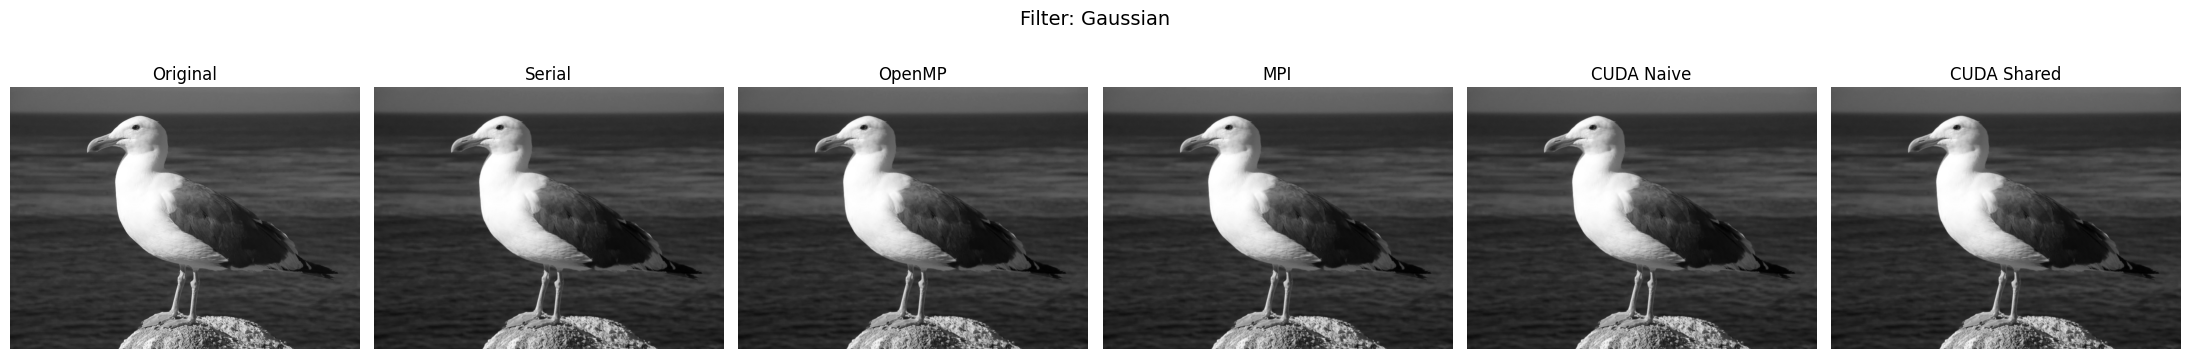

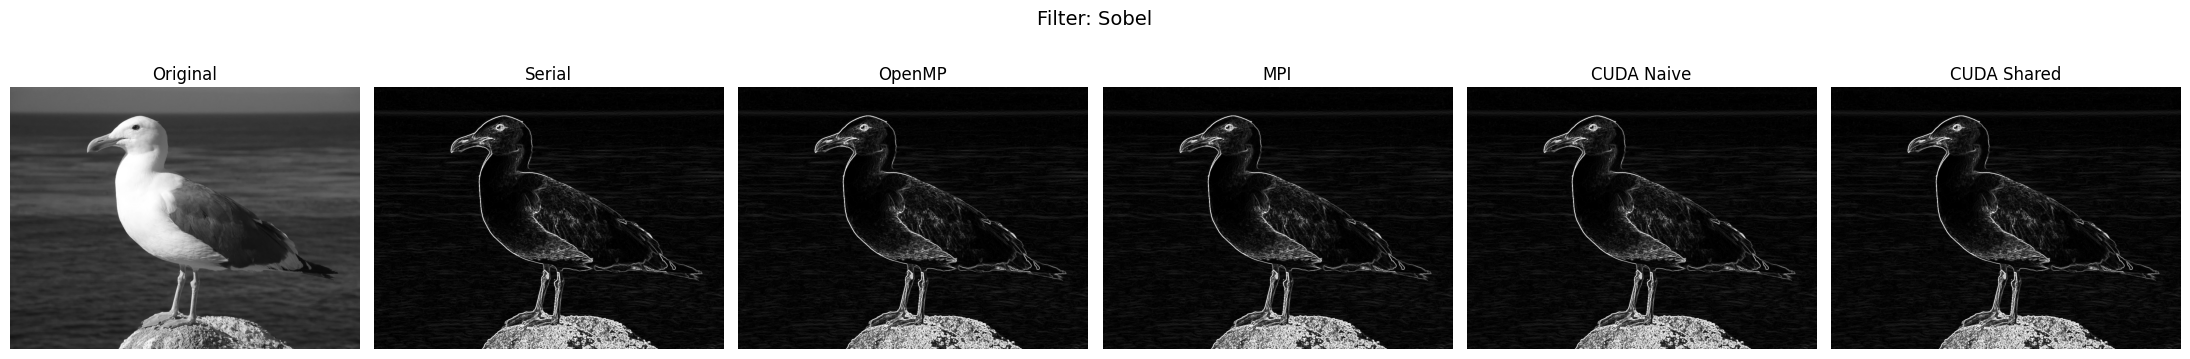

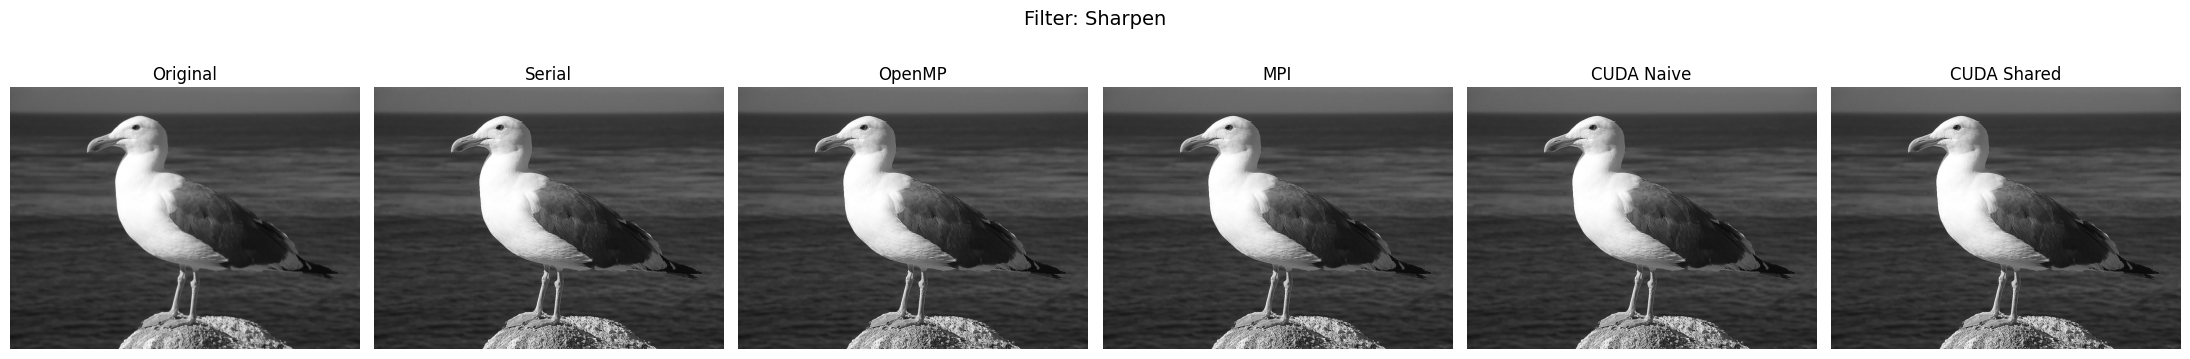

In [23]:
import matplotlib.pyplot as plt
import numpy as np

with open('image_dims.txt') as f:
    width, height = map(int, f.read().split())

def load_bin(filename):
    return np.fromfile(filename, dtype=np.uint8).reshape(height, width)

original = np.fromfile('image.bin', dtype=np.uint8).reshape(height, width)
filter_names = ['Gaussian', 'Sobel', 'Sharpen']
method_files = {
    'Serial': 'output_serial_{}.bin',
    'OpenMP': 'output_openmp_{}.bin',
    'MPI': 'output_mpi_{}.bin',
    'CUDA Naive': 'output_cuda_naive_{}.bin',
    'CUDA Shared': 'output_cuda_shared_{}.bin',
}

for fid, fname in enumerate(filter_names):
    fig, axes = plt.subplots(1, 6, figsize=(22, 4))
    axes[0].imshow(original, cmap='gray')
    axes[0].set_title('Original')
    axes[0].axis('off')

    for ax, (method, pattern) in zip(axes[1:], method_files.items()):
        try:
            img_ = load_bin(pattern.format(fid))
            ax.imshow(img_, cmap='gray')
            ax.set_title(method)
        except FileNotFoundError:
            ax.set_title(method + ' (missing)')
        ax.axis('off')

    fig.suptitle(f'Filter: {fname}', fontsize=14)
    plt.tight_layout()
    plt.show()

## 10. Profiling with Nsight Systems / nvprof

On modern Colab GPUs (T4/A100), the legacy `nvprof` is replaced by **Nsight Systems** (`nsys`) and **Nsight Compute** (`ncu`). Both are usually pre-installed in the Colab CUDA toolkit image.

- `nsys profile` gives a timeline: kernel launches, memory copies, API overhead.
- `ncu` gives detailed per-kernel metrics: occupancy, memory throughput, achieved bandwidth — useful to **explain why the shared-memory version is faster** than naive.

If `nvprof` happens to be available (older CUDA images), the equivalent command is `!nvprof ./cuda_naive 0`.

In [24]:
# Check which profiling tools are available
!which nsys ncu nvprof || echo 'Some tools may not be present - that is OK, use whichever is found'

/usr/local/cuda/bin/ncu
/usr/local/cuda/bin/nvprof
Some tools may not be present - that is OK, use whichever is found


In [25]:
# Nsight Systems timeline profile - naive vs shared (Gaussian filter)
!nsys profile --stats=true -o profile_naive ./cuda_naive 0
!nsys profile --stats=true -o profile_shared ./cuda_shared 0

/bin/bash: line 1: nsys: command not found
/bin/bash: line 1: nsys: command not found


In [26]:
# Nsight Compute - detailed kernel metrics (occupancy, memory throughput)
# This compares global memory efficiency between naive and shared-memory kernels
!ncu --set basic ./cuda_naive 0
!ncu --set basic ./cuda_shared 0

==PROF== Connected to process 3673 (/content/cuda_naive)
==PROF== Profiling "convolutionNaive" - 0: 0%....50%....100% - 9 passes
CUDA Naive Gaussian: 2306.1204 ms (1200x900)
==PROF== Disconnected from process 3673
[3673] cuda_naive@127.0.0.1
  convolutionNaive(unsigned char *, unsigned char *, int, int, int) (75, 57, 1)x(16, 16, 1), Context 1, Stream 7, Device 0, CC 7.5
    Section: GPU Speed Of Light Throughput
    ----------------------- ----------- ------------
    Metric Name             Metric Unit Metric Value
    ----------------------- ----------- ------------
    DRAM Frequency                  Ghz         4.96
    SM Frequency                    Mhz       584.64
    Elapsed Cycles                cycle       35,070
    Memory Throughput                 %        58.14
    DRAM Throughput                   %        25.15
    Duration                         us        59.97
    L1/TEX Cache Throughput           %        80.12
    L2 Cache Throughput               %        15.61
 

**What to look for in the `ncu` output** (for your report):
- **Memory Throughput / DRAM Throughput**: the naive kernel should show higher global memory traffic per output pixel (each pixel reads up to 9 global memory locations) vs. shared (each pixel loaded from global memory ~once per block, then reused from shared memory).
- **Achieved Occupancy**: how many warps are active vs. theoretical max — both kernels should have similar occupancy since block size is the same, but shared memory usage may reduce occupancy slightly due to register/shared-memory pressure.
- **Duration**: directly compare kernel execution time between the two `ncu` runs — this should match the `cudaEvent` timings from sections 7-8.

If `ncu` requires elevated permissions and fails in Colab with a permissions error, fall back to `nsys` output (Section 10, first profiling cell) — the timeline `.qdrep`/`.nsys-rep` file can be downloaded and opened in Nsight Systems GUI locally for screenshots in your report.

## 11. Full Benchmark: All 5 Methods x 3 Filters x Multiple Sizes

This is the core experimental data for your report. We generate random grayscale images at increasing resolutions and time every (method, filter) combination.

In [27]:
%%writefile benchmark.py
import numpy as np
import subprocess
import re
import csv

sizes = [256, 512, 1024, 2048, 4096]
filters = [0, 1, 2]  # Gaussian, Sobel, Sharpen
filter_names = ['Gaussian', 'Sobel', 'Sharpen']
results = []

def extract_ms(output):
    m = re.search(r'([\d.]+) ms', output)
    return float(m.group(1)) if m else None

for size in sizes:
    width, height = size, size
    arr = np.random.randint(0, 256, (height, width), dtype=np.uint8)
    arr.tofile('image.bin')
    with open('image_dims.txt', 'w') as f:
        f.write(f'{width} {height}')

    for fid in filters:
        row = {'size': f'{width}x{height}', 'filter': filter_names[fid]}

        out = subprocess.run(['./serial', str(fid)], capture_output=True, text=True).stdout
        row['serial_ms'] = extract_ms(out)

        out = subprocess.run(['./openmp_filter', str(fid)], capture_output=True, text=True).stdout
        row['openmp_ms'] = extract_ms(out.split('\n')[1])

        out = subprocess.run(['mpirun', '--allow-run-as-root', '--oversubscribe', '-np', '4',
                               './mpi_filter', str(fid)], capture_output=True, text=True).stdout
        row['mpi_ms'] = extract_ms(out)

        out = subprocess.run(['./cuda_naive', str(fid)], capture_output=True, text=True).stdout
        row['cuda_naive_ms'] = extract_ms(out)

        out = subprocess.run(['./cuda_shared', str(fid)], capture_output=True, text=True).stdout
        row['cuda_shared_ms'] = extract_ms(out)

        results.append(row)
        print(row)

with open('benchmark_results.csv', 'w', newline='') as f:
    writer = csv.DictWriter(f, fieldnames=results[0].keys())
    writer.writeheader()
    writer.writerows(results)

print('Done. Results saved to benchmark_results.csv')

Writing benchmark.py


In [28]:
!python3 benchmark.py

{'size': '256x256', 'filter': 'Gaussian', 'serial_ms': 2.02038, 'openmp_ms': 2.20064, 'mpi_ms': 0.699206, 'cuda_naive_ms': 0.2697, 'cuda_shared_ms': 0.2929}
{'size': '256x256', 'filter': 'Sobel', 'serial_ms': 1.88402, 'openmp_ms': 3.9788, 'mpi_ms': 1.89173, 'cuda_naive_ms': 0.2721, 'cuda_shared_ms': 0.2897}
{'size': '256x256', 'filter': 'Sharpen', 'serial_ms': 1.62557, 'openmp_ms': 1.52974, 'mpi_ms': 0.853815, 'cuda_naive_ms': 0.2717, 'cuda_shared_ms': 0.3327}
{'size': '512x512', 'filter': 'Gaussian', 'serial_ms': 4.42071, 'openmp_ms': 4.45837, 'mpi_ms': 4.71754, 'cuda_naive_ms': 0.3258, 'cuda_shared_ms': 0.2838}
{'size': '512x512', 'filter': 'Sobel', 'serial_ms': 7.69811, 'openmp_ms': 7.14086, 'mpi_ms': 6.55999, 'cuda_naive_ms': 0.297, 'cuda_shared_ms': 0.2923}
{'size': '512x512', 'filter': 'Sharpen', 'serial_ms': 6.83241, 'openmp_ms': 5.5408, 'mpi_ms': 9.83707, 'cuda_naive_ms': 0.3151, 'cuda_shared_ms': 0.2861}
{'size': '1024x1024', 'filter': 'Gaussian', 'serial_ms': 17.7434, 'openmp

## 12. Result Plots and Analysis

         size    filter  serial_ms  openmp_ms      mpi_ms  cuda_naive_ms  \
0     256x256  Gaussian    2.02038    2.20064    0.699206         0.2697   
1     256x256     Sobel    1.88402    3.97880    1.891730         0.2721   
2     256x256   Sharpen    1.62557    1.52974    0.853815         0.2717   
3     512x512  Gaussian    4.42071    4.45837    4.717540         0.3258   
4     512x512     Sobel    7.69811    7.14086    6.559990         0.2970   
5     512x512   Sharpen    6.83241    5.54080    9.837070         0.3151   
6   1024x1024  Gaussian   17.74340   18.06740   18.849800         0.3329   
7   1024x1024     Sobel   51.90900   49.86500   62.556200         0.3241   
8   1024x1024   Sharpen   38.60730   48.64340   42.813700         0.2518   
9   2048x2048  Gaussian   68.40820   70.32250  128.420000         0.3337   
10  2048x2048     Sobel  123.16000  112.94900  135.874000         0.4024   
11  2048x2048   Sharpen  105.22500   88.75270  156.087000         0.3639   
12  4096x409

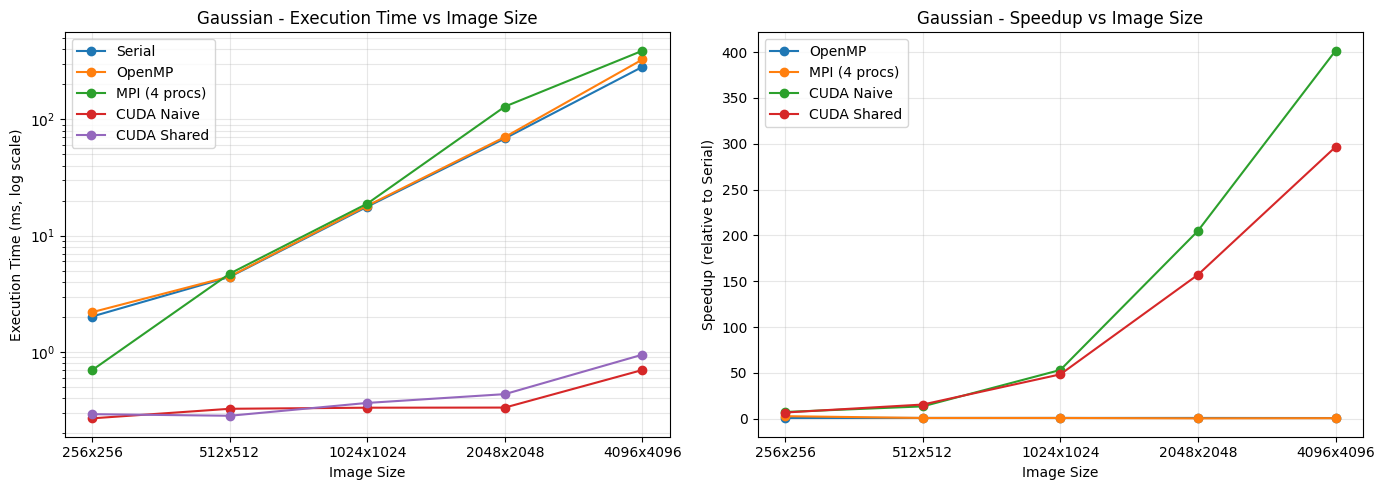

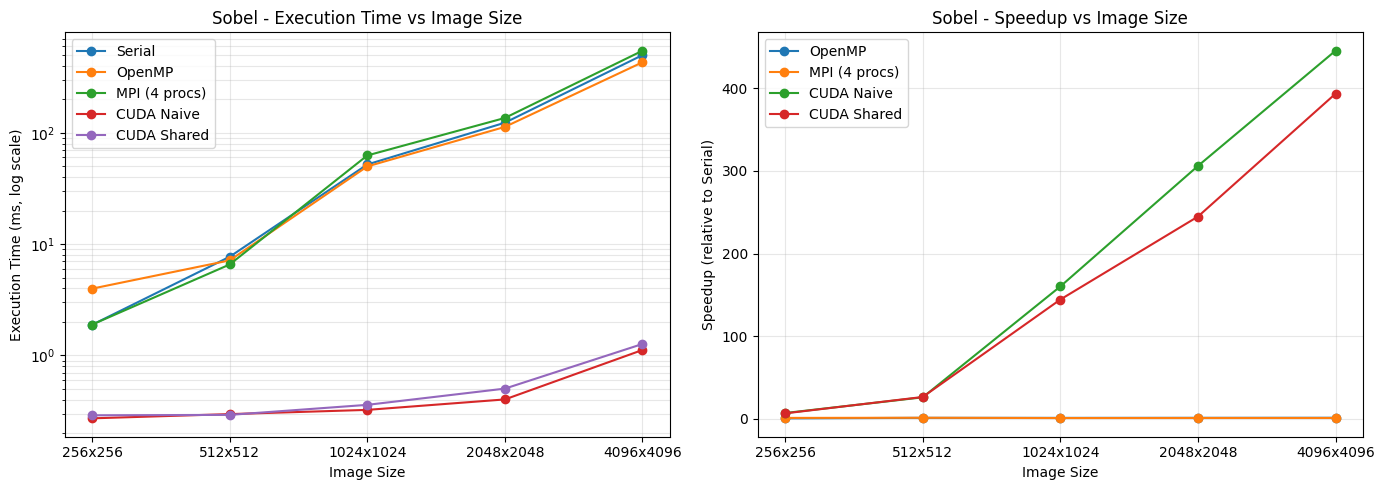

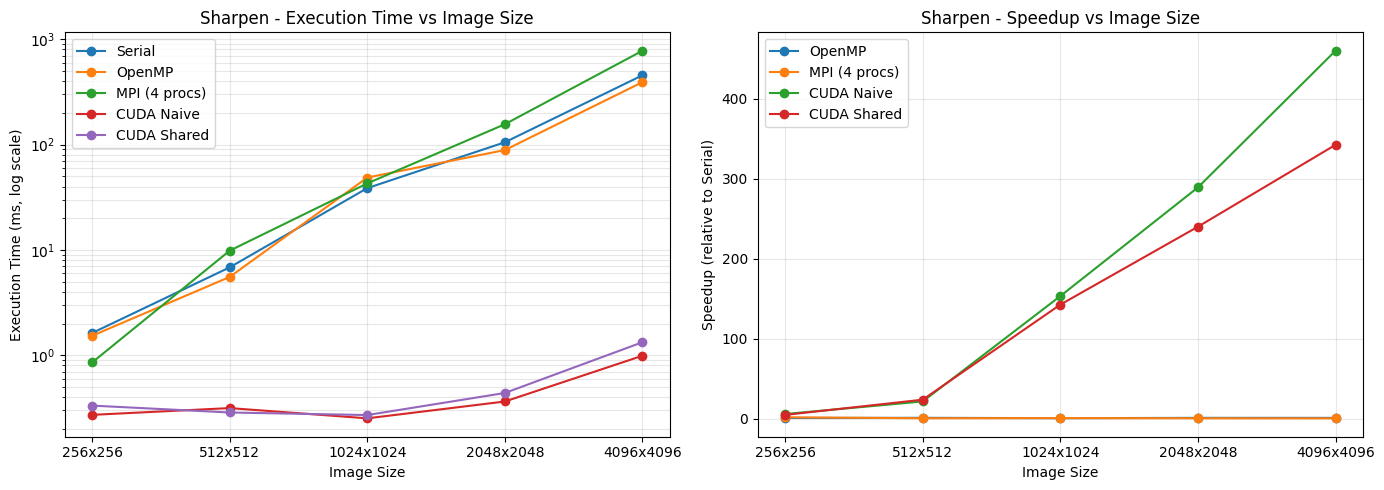

In [29]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('benchmark_results.csv')
print(df)

methods = [('serial_ms', 'Serial'), ('openmp_ms', 'OpenMP'), ('mpi_ms', 'MPI (4 procs)'),
            ('cuda_naive_ms', 'CUDA Naive'), ('cuda_shared_ms', 'CUDA Shared')]

for fname in df['filter'].unique():
    sub = df[df['filter'] == fname]

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    for col, label in methods:
        axes[0].plot(sub['size'], sub[col], marker='o', label=label)
    axes[0].set_yscale('log')
    axes[0].set_xlabel('Image Size')
    axes[0].set_ylabel('Execution Time (ms, log scale)')
    axes[0].set_title(f'{fname} - Execution Time vs Image Size')
    axes[0].legend()
    axes[0].grid(True, which='both', alpha=0.3)

    for col, label in methods[1:]:
        speedup = sub['serial_ms'] / sub[col]
        axes[1].plot(sub['size'], speedup, marker='o', label=label)
    axes[1].set_xlabel('Image Size')
    axes[1].set_ylabel('Speedup (relative to Serial)')
    axes[1].set_title(f'{fname} - Speedup vs Image Size')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(f'benchmark_plot_{fname.lower()}.png', dpi=150)
    plt.show()

## 13. Notes for Your Report

**Correctness (Section 9)**: all five outputs per filter should look visually identical — confirms OpenMP, MPI, and both CUDA versions are correct relative to the serial baseline.

**Expected performance trends:**
- **Serial vs OpenMP**: speedup roughly tracks CPU core count (Colab gives ~2 vCPUs, so expect modest ~1.5-2x).
- **Serial vs MPI**: with 4 processes oversubscribed on ~2 cores, expect speedup similar to or slightly less than OpenMP at small sizes (communication/halo-exchange overhead dominates), but the *scaling pattern* matters more than raw numbers — discuss how speedup would improve on a real multi-node cluster with more physical cores.
- **Serial vs CUDA**: should dramatically outperform all CPU methods at large sizes (2048x2048+), often 50-200x.
- **CUDA Naive vs Shared**: shared memory version should be faster at large sizes due to reduced global memory traffic — confirm this with the `ncu` memory throughput numbers from Section 10.

**Distributed-computing discussion points (MPI):**
- Domain decomposition strategy: row-block partitioning, why row-blocks (simple halo exchange) vs. 2D block decomposition (more complex but better for very wide images).
- Communication overhead: halo exchange is O(width) per boundary per iteration — discuss how this scales with number of processes vs. local computation O(width x localRows).
- Load balancing: remainder rows distributed to first `remainder` ranks — discuss what happens with uneven image sizes.
- Scalability: discuss strong scaling (fixed problem size, increasing processes) vs weak scaling (problem size grows with processes) — you could add an extra experiment varying `-np` (e.g. 1, 2, 4, 8) at a fixed image size.

**Profiling discussion (Section 10):**
- Use `nsys` timeline to show kernel launch overhead is negligible at large sizes but dominates at small sizes (explains why CUDA speedup is poor for 256x256).
- Use `ncu` memory metrics to quantitatively justify the shared-memory optimization (cite specific throughput numbers).

**Possible further extensions:**
- Vary MPI process count (1, 2, 4, 8) at fixed image size — strong scaling graph.
- Try different CUDA block sizes (8x8, 16x16, 32x32) and plot effect on performance.
- Hybrid MPI + CUDA: each MPI process offloads its block to GPU (if multiple GPUs available).